# SST-2 FlexLoRA Pipeline：不同方法的加权误差

读取本目录中的 4 个 CSV，并绘制各方法每轮的 `weighted_error`。

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PIPELINE_NAME = 'flexlora_pipeline'
DATASET_NAME = 'SST-2'
DATA_DIR = Path.cwd()
if not list(DATA_DIR.glob('*.csv')):
    DATA_DIR = Path('close-optimal-result/aggregation_broadcast_error/sst2') / PIPELINE_NAME

csv_files = sorted(DATA_DIR.glob('*.csv'))
if not csv_files:
    raise FileNotFoundError(f'在 {DATA_DIR.resolve()} 中没有找到 CSV 文件')

required_columns = {'round', 'evaluated_method', 'weighted_error'}
frames = []
for csv_file in csv_files:
    frame = pd.read_csv(csv_file)
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f'{csv_file.name} 缺少列: {sorted(missing)}')
    frame = frame.copy()
    frame['source_file'] = csv_file.name
    frames.append(frame)

data = pd.concat(frames, ignore_index=True)
data['round'] = pd.to_numeric(data['round'], errors='coerce')
data['weighted_error'] = pd.to_numeric(data['weighted_error'], errors='coerce')
data = data.dropna(subset=['round', 'weighted_error']).sort_values(['evaluated_method', 'round'])
print(f'Dataset: {DATASET_NAME} | Pipeline: {PIPELINE_NAME}')
print(f'读取文件数: {len(csv_files)}')
print('方法:', ', '.join(sorted(data['evaluated_method'].unique())))
data[['evaluated_method', 'round', 'weighted_error', 'source_file']].head()

Dataset: SST-2 | Pipeline: flexlora_pipeline
读取文件数: 4
方法: fedss_0_2, rbla, sp, zeropadding


,evaluated_method,round,weighted_error,source_file
0,fedss_0_2,0,29.303107,sp_fedss_1_0_sst2_-aggregation_broadcast_train...
1,fedss_0_2,1,4.839467,sp_fedss_1_0_sst2_-aggregation_broadcast_train...
2,fedss_0_2,2,3.918326,sp_fedss_1_0_sst2_-aggregation_broadcast_train...
3,fedss_0_2,3,3.567130,sp_fedss_1_0_sst2_-aggregation_broadcast_train...
4,fedss_0_2,4,3.466819,sp_fedss_1_0_sst2_-aggregation_broadcast_train...


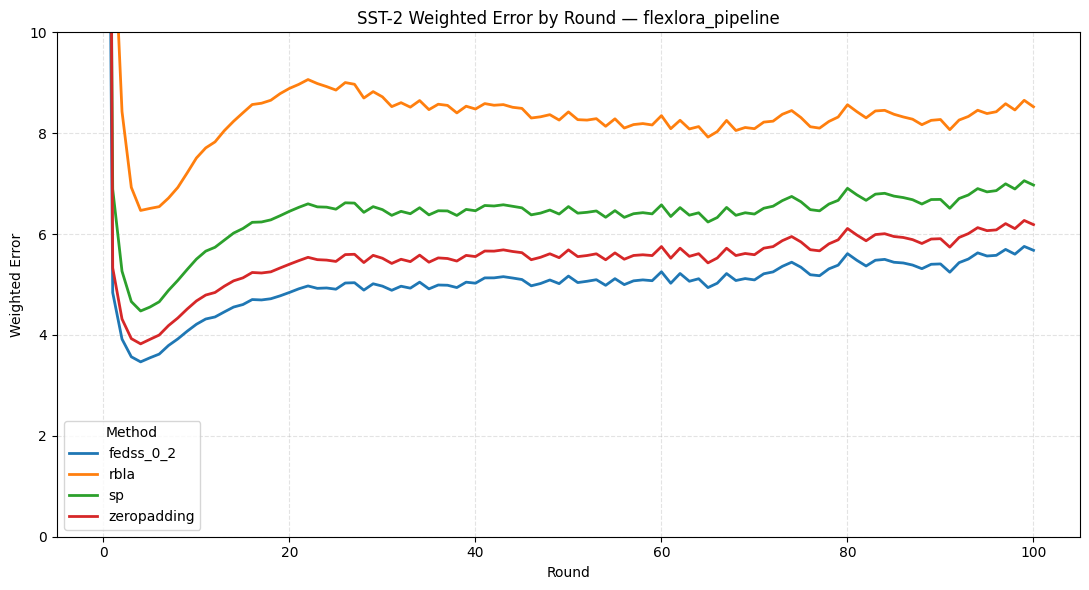

In [4]:
fig, ax = plt.subplots(figsize=(11, 6))
for method, method_data in data.groupby('evaluated_method', sort=True):
    ax.plot(method_data['round'], method_data['weighted_error'], label=method, linewidth=2)

ax.set_ylim(0, 10)
ax.set_xlabel('Round')
ax.set_ylabel('Weighted Error')
ax.set_title(f'{DATASET_NAME} Weighted Error by Round — {PIPELINE_NAME}')
ax.grid(True, linestyle='--', alpha=0.35)
ax.legend(title='Method')
fig.tight_layout()
plt.show()